In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, 
    roc_curve, roc_auc_score, RocCurveDisplay
)
from tensorflow.keras.callbacks import ModelCheckpoint
import tensorflow as tf
import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.applications import ResNet50

2026-06-11 12:34:56.075906: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781181296.282586      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781181296.344808      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781181296.852723      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781181296.852764      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781181296.852767      57 computation_placer.cc:177] computation placer alr

In [2]:
AUTOTUNE = tf.data.AUTOTUNE

csv_path = '/kaggle/input/datasets/ambarish/breakhis/Folds.csv'

img_dir = '/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/'

data = pd.read_csv(csv_path)
class_names = ['benign', 'malignant']

print("دیتاست با موفقیت لود شد! تعداد کل سطرها:", len(data))
print(data.head(3))

دیتاست با موفقیت لود شد! تعداد کل سطرها: 39545
   fold  mag    grp                                           filename
0     1  100  train  BreaKHis_v1/histology_slides/breast/benign/SOB...
1     1  100  train  BreaKHis_v1/histology_slides/breast/benign/SOB...
2     1  100  train  BreaKHis_v1/histology_slides/breast/benign/SOB...


In [3]:
# استخراج برچسب‌ها از روی مسیر فایل
data['label'] = data['filename'].apply(lambda x: 'benign' if 'benign' in x else 'malignant')

In [4]:
data['patient_id'] = data['filename'].apply(
    lambda x: x.split('-')[0] + '-' + x.split('-')[1]
)
patients = data['patient_id'].unique()


In [5]:
print(data.columns)


Index(['fold', 'mag', 'grp', 'filename', 'label', 'patient_id'], dtype='object')


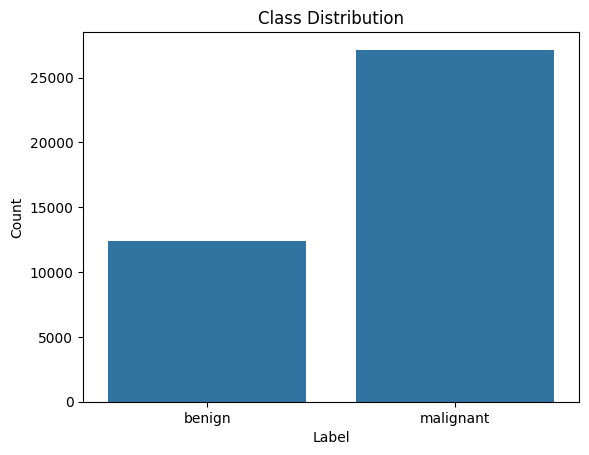

Count of Benign    : 12400
Count of Malignant : 27145


In [6]:
sns.countplot(data=data, x="label")

plt.title("Class Distribution")
plt.xlabel("Label")
plt.ylabel("Count")

plt.show()

# تعداد هر کلاس
print("Count of Benign    :", (data["label"] == "benign").sum())
print("Count of Malignant :", (data["label"] == "malignant").sum())

In [18]:
train_val_patients, test_patients = train_test_split(
    patients,
    test_size=0.15,
    random_state=42
)

# 2. جدا کردن train و validation
train_patients, valid_patients = train_test_split(
    train_val_patients,
    test_size=0.2,
    random_state=42
)


In [19]:
train_df = data[data['patient_id'].isin(train_patients)].reset_index(drop=True)
valid_df = data[data['patient_id'].isin(valid_patients)].reset_index(drop=True)
test_df  = data[data['patient_id'].isin(test_patients)].reset_index(drop=True)

In [20]:
print("\nSplit sizes:")
print("Train:", len(train_df))
print("Valid:", len(valid_df))
print("Test :", len(test_df))



Split sizes:
Train: 26840
Valid: 7295
Test : 5410


In [ ]:
train_df['set'] = 'train'
valid_df['set'] = 'valid'
test_df['set'] = 'test'

data_new = pd.concat([train_df, valid_df, test_df], ignore_index=True)

import seaborn as sns

sns.displot(
    data=data_new,
    x='label',
    col='set'
)

In [ ]:
#weights_path = '/kaggle/input/datasets/soroushgholami/resnet50-weight/RadImageNet-ResNet50_notop.h5'

In [11]:
# تعداد کل نمونه‌های بخش آموزش
total_train_samples = len(train_df)

# تعداد نمونه‌های هر کلاس
count_benign = len(train_df[train_df['label'] == 'benign'])
count_malignant = len(train_df[train_df['label'] == 'malignant'])

# فرمول استاندارد وزن‌دهی: total / (2 * class_count)
# دقت کن که ایندکس 0 برای benign و ایندکس 1 برای malignant است
class_weight_dict = {
    0: total_train_samples / (2.0 * count_benign),
    1: total_train_samples / (2.0 * count_malignant)
}

print("✅ وزن‌های محاسبه شده برای بالانس دیتای ترِین:")
print(class_weight_dict)

✅ وزن‌های محاسبه شده برای بالانس دیتای ترِین:
{0: 1.556844547563805, 1: 0.7365532381997805}


In [23]:
BATCH_SIZE = 24
IMG_SIZE = (224, 224)

# =========================
# TRAIN DATA (with augmentation)
# =========================
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # مهم برای ResNet
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='reflect'
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=img_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

# =========================
# VALIDATION DATA (NO AUGMENTATION)
# =========================
valid_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

valid_generator = valid_datagen.flow_from_dataframe(
    dataframe=valid_df,
    directory=img_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 26840 validated image filenames belonging to 2 classes.
Found 7295 validated image filenames belonging to 2 classes.


In [ ]:
base_model = ResNet50(
    include_top=False,
    weights="imagenet",   # اگر فایل custom داری هم می‌تونی جایگزین کنی
    input_shape=(224, 224, 3),
    pooling="avg"
)

# =========================
# 2. مرحله اول: Freeze کامل (Feature Extraction)
# =========================
base_model.trainable = False

# =========================
# 3. Head مدل
# =========================
inputs = keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)

x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(2, activation="softmax")(x)

model = keras.Model(inputs, outputs)

# =========================
# 4. Compile مرحله 1 (warm-up)
# =========================
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

model.summary()

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

print("\n--- آغاز فرآیند آموزش مدل روی کگل ---")

# =========================
# 1. ModelCheckpoint (بهینه‌تر)
# =========================
checkpoint_cb = ModelCheckpoint(
    filepath='breakhis_resnet50_best.keras',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=False,
    mode='min',
    verbose=1
)

# =========================
# 2. EarlyStopping (اصلاح‌شده)
# =========================
early_stopping_cb = EarlyStopping(
    monitor='val_loss',
    patience=5,   # کمی بیشتر از 3 برای stability
    mode='min',
    restore_best_weights=True,
    verbose=1
)

# =========================
# 3. Learning Rate Scheduler (خیلی مهم برای ResNet)
# =========================
reduce_lr_cb = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# =========================
# 4. Training
# =========================
history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=20,   # 17 خیلی محدود بود
    validation_data=valid_generator,
    validation_steps=len(valid_generator),
    class_weight=class_weight_dict,
    callbacks=[
        checkpoint_cb,
        early_stopping_cb,
        reduce_lr_cb
    ]
)

# =========================
# 5. Save final model
# =========================
model.save('breakhis_resnet50_final.keras')

print("✅ مدل ResNet50 با موفقیت ذخیره شد!")

In [22]:
from tensorflow.keras.models import load_model

# مسیر دقیق و قطعی مدل شما در کگل
model_path = "/kaggle/input/notebooks/soroushgholami/brakehis1/breakhis_resnet50_best.keras"

# بارگذاری مدل
model = load_model(model_path)



NameError: name 'test_ds' is not defined

In [24]:
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input  # اعمال همان پیش‌پردازش رزنیت
)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    directory=img_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical', # دقیقاً مشابه ترین و ولیدیشن
    shuffle=False             # بسیار مهم: برای تست جابه‌جا نشود
)

# =========================
# EVALUATE MODEL
# =========================
results = model.evaluate(test_generator, verbose=1)
print("Loss and Accuracy on Test Set:", results)

Found 5410 validated image filenames belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1781183382.019907     135 service.cc:152] XLA service 0x79666c04bc40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781183382.019963     135 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1781183382.019969     135 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1781183382.957946     135 cuda_dnn.cc:529] Loaded cuDNN version 91002


  2/226 ━━━━━━━━━━━━━━━━━━━━ 14s 64ms/step - accuracy: 0.9375 - auc: 0.9844 - loss: 0.2118

I0000 00:00:1781183387.542090     135 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


226/226 ━━━━━━━━━━━━━━━━━━━━ 98s 394ms/step - accuracy: 0.8886 - auc: 0.9416 - loss: 0.4787
Loss and Accuracy on Test Set: [0.5380864143371582, 0.8770794868469238, 0.93193519115448]


In [26]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# ۱. گرفتن پیش‌بینی‌های مدل برای داده‌های تست
predictions = model.predict(test_generator, verbose=1)
# تبدیل احتمالات خروجی به لیبل‌های ۰ و ۱ (یا کلاس‌های نهایی)
predicted_classes = np.argmax(predictions, axis=1)

# ۲. گرفتن لیبل‌های واقعی از ژنراتور
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# ۳. چاپ گزارش طبقه‌بندی (Precision, Recall, F1-Score)
print("Classification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# ۴. چاپ ماتریس آشفتگی
print("Confusion Matrix:")
print(confusion_matrix(true_classes, predicted_classes))

226/226 ━━━━━━━━━━━━━━━━━━━━ 72s 320ms/step
Classification Report:
              precision    recall  f1-score   support

      benign       0.71      0.94      0.81      1495
   malignant       0.98      0.85      0.91      3915

    accuracy                           0.88      5410
   macro avg       0.84      0.90      0.86      5410
weighted avg       0.90      0.88      0.88      5410

Confusion Matrix:
[[1410   85]
 [ 580 3335]]


In [33]:
from sklearn.metrics import roc_auc_score
import numpy as np

# پیش‌بینی احتمال‌ها
y_pred = model.predict(test_generator, verbose=1)

# برچسب‌های واقعی
y_true = test_generator.classes

# چون class_mode='categorical' است و دو کلاس داری
auc = roc_auc_score(y_true, y_pred[:, 1])

print("Test ROC-AUC:", auc)

226/226 ━━━━━━━━━━━━━━━━━━━━ 72s 316ms/step
Test ROC-AUC: 0.955975003951016


In [ ]:
|